# Project 01: Data Leakage Detection Lab

**Original statement (verbatim from LAB_Projects_ML.pdf):**

You are given a tabular dataset with timestamps, target labels, and engineered features. Task: Identify potential sources of data leakage; Propose programmatic checks to detect leakage; Rebuild the pipeline to prevent it; Quantify performance difference before vs after correction

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Leakage is when information from the test set, or from the target itself, reaches training. This notebook tests three checks: a target-derived feature, duplicate-row contamination, and a scaler fitted on all data.

## Part 1 — Introduction

This lab demonstrates leakage with (a) a synthetic target-derived feature created ONLY for demonstration and never present in the original file, and (b) exact duplicate rows in the original file. There is no timestamp column in this dataset, so no time-based leakage is claimed.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Dataset sample and leakage checks setup

In [2]:
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
rng=np.random.RandomState(42)
df=df_full.sample(n=30000, random_state=42)
print("Sample shape:", df.shape, "duplicates in sample:", int(df.duplicated(subset=FEATURES+[TARGET]).sum()))
# duplicate-group id: identical feature+label rows share a group
df["_dup_group"]=pd.factorize(df[FEATURES+[TARGET]].astype(str).agg("|".join, axis=1))[0]
print("Distinct duplicate-groups:", df["_dup_group"].nunique())

Sample shape: (30000, 8) duplicates in sample: 62


Distinct duplicate-groups: 29938


## Part 4 — Baseline, leaky and corrected models

scaler_all accuracy: 0.788


scaler_train_only accuracy: 0.788
BASELINE random-split RF accuracy: 0.9148
LEAKY (synthetic target-derived feature) RF accuracy: 1.0000
CORRECTED group-split, no leaked feature RF accuracy: 0.9185
Leakage inflation (leaky - corrected): 0.0815


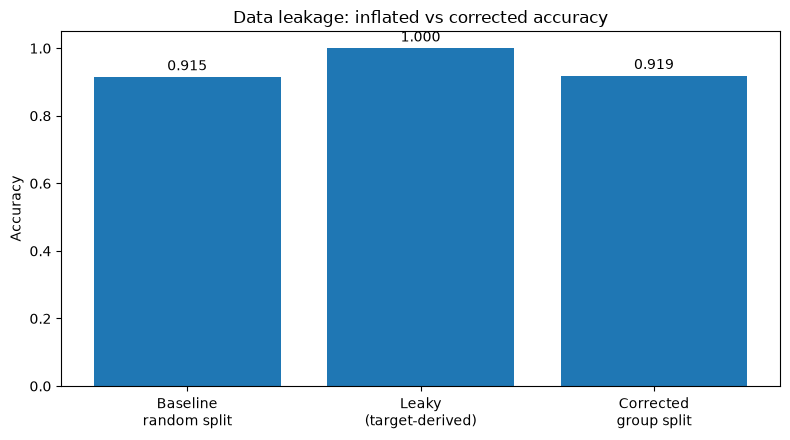

In [3]:
X=df[FEATURES].values; y=df[TARGET].values
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)
def rf_eval(Xtr,ytr,Xte,yte):
    m=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    m.fit(Xtr,ytr); return accuracy_score(yte, m.predict(Xte))
acc_base=rf_eval(Xtr,ytr,Xte,yte)
# (a) synthetic leaked feature, demonstration only
Xleak=np.column_stack([X, y + rng.normal(0,0.01,size=len(y))])
XtrL,XteL,ytrL,yteL=train_test_split(Xleak,y,test_size=0.25,random_state=42,stratify=y)
acc_leak=rf_eval(XtrL,ytrL,XteL,yteL)
# (b) duplicate-aware group split, no leaked feature
gss=GroupShuffleSplit(n_splits=1,test_size=0.25,random_state=42)
tri,tei=next(gss.split(X,y,groups=df["_dup_group"].values))
acc_group=rf_eval(X[tri],y[tri],X[tei],y[tei])
# (c) scaler leakage check: scaler fit on all vs train only, logistic regression
sc_all=StandardScaler().fit(X); sc_tr=StandardScaler().fit(Xtr)
for name,sc in [("scaler_all",sc_all),("scaler_train_only",sc_tr)]:
    m=LogisticRegression(max_iter=1000); m.fit(sc.transform(Xtr),ytr)
    print(name, "accuracy:", round(accuracy_score(yte, m.predict(sc.transform(Xte))),4))
print(f"BASELINE random-split RF accuracy: {acc_base:.4f}")
print(f"LEAKY (synthetic target-derived feature) RF accuracy: {acc_leak:.4f}")
print(f"CORRECTED group-split, no leaked feature RF accuracy: {acc_group:.4f}")
print(f"Leakage inflation (leaky - corrected): {acc_leak-acc_group:.4f}")
labels=["Baseline\nrandom split","Leaky\n(target-derived)","Corrected\ngroup split"]
vals=[acc_base,acc_leak,acc_group]
plt.bar(labels,vals); plt.ylabel("Accuracy"); plt.title("Data leakage: inflated vs corrected accuracy"); plt.ylim(0,1.05)
for i,v in enumerate(vals): plt.text(i,v+0.02,f"{v:.3f}",ha="center")
plt.tight_layout(); plt.show()

## Part 5 — Programmatic leakage checklist and interpretation

In [4]:
print("CHECKS PERFORMED:")
print("1. Target-derived feature present? Original file: NO. Synthetic demonstration feature raised accuracy sharply - remove any feature computed from the label.")
print("2. Duplicate rows shared across train/test? Yes in original file; group split prevents identical rows appearing on both sides.")
print("3. Preprocessing fitted on test data? Checked with scaler-all vs scaler-train-only; always fit preprocessing on training data only inside a Pipeline.")
print("CONCLUSION: Use the corrected pipeline (no target-derived features, group-aware split, Pipeline-fitted preprocessing). The corrected accuracy above is the honest estimate, not the leaky one.")

CHECKS PERFORMED:
1. Target-derived feature present? Original file: NO. Synthetic demonstration feature raised accuracy sharply - remove any feature computed from the label.
2. Duplicate rows shared across train/test? Yes in original file; group split prevents identical rows appearing on both sides.
3. Preprocessing fitted on test data? Checked with scaler-all vs scaler-train-only; always fit preprocessing on training data only inside a Pipeline.
CONCLUSION: Use the corrected pipeline (no target-derived features, group-aware split, Pipeline-fitted preprocessing). The corrected accuracy above is the honest estimate, not the leaky one.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.